# AP-2: Orbital Elements Explorer

Converts between classical orbital elements and ECI state vectors with the `toolkit` package, verifies the round trip, and shows how each element shapes or orients an orbit.

| Section | What |
|---|---|
| A | Convert the ISS-like reference orbit both ways |
| B | Round-trip error on several orbits (target < 1e-6) |
| C | Inclination sweep, 0° to 90° (figure 1) |
| D | One orbit with node, periapsis and velocity annotated (figure 2) |
| E | Time on the orbit: Kepler's equation and Molniya |
| F | Which elements a manoeuvre changes cheaply |

All logic lives in the `toolkit` package; this notebook only calls it.

In [1]:
import sys
from pathlib import Path

REPO = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(REPO) not in sys.path:
    sys.path.insert(0, str(REPO))          # make the toolkit package importable

import matplotlib.pyplot as plt
import numpy as np

from toolkit.constants import FIGURES_DIR, MU_KM3_S2, R_EARTH_KM
from toolkit.conversions import coe_to_rv, roundtrip, rv_to_coe
from toolkit.kepler import mean_motion, period_s, propagate, time_since_periapsis

np.set_printoptions(precision=4, suppress=True)
FIGURES_DIR.mkdir(exist_ok=True)

## A. Both conversions on the reference orbit

ISS-like: a = 6,778 km, e = 0.0005, i = 51.64°, Ω = ω = ν = 0.

In [2]:
REFERENCE = dict(a_km=6778.0, e=0.0005, i_deg=51.64, raan_deg=0.0, argp_deg=0.0, nu_deg=0.0)

r, v = coe_to_rv(**REFERENCE)
print("r (km)  :", r)
print("v (km/s):", v)

back = rv_to_coe(r, v)
for key, value in REFERENCE.items():
    print(f"{key:9s} in {value:10.4f}   out {back[key]:10.4f}")

r (km)  : [6774.611    0.       0.   ]
v (km/s): [0.     4.7615 6.0162]
a_km      in  6778.0000   out  6778.0000
e         in     0.0005   out     0.0005
i_deg     in    51.6400   out    51.6400
raan_deg  in     0.0000   out     0.0000
argp_deg  in     0.0000   out     0.0000
nu_deg    in     0.0000   out     0.0000


## B. Round-trip error

Elements → (r, v) → elements → (r, v). `roundtrip` returns the worst error: a relative, e absolute, angles as a fraction of a full turn, and the relative change in r and v.

In [3]:
TEST_ORBITS = {
    "ISS-like":           (6778.0, 0.0005, 51.64, 0.0, 0.0, 0.0),
    "Molniya":            (26560.0, 0.74, 63.4, 0.0, 270.0, 0.0),
    "GEO (near-singular)": (42164.0, 0.0001, 0.05, 0.0, 0.0, 0.0),
    "Retrograde":         (7000.0, 0.1, 141.0, 250.0, 30.0, 200.0),
    "Worked example":     (10000.0, 0.3, 30.0, 40.0, 60.0, 45.0),
}

TARGET = 1e-6
print(f"{'Orbit':22s}{'max error':>12s}")
errors = []
for name, coe in TEST_ORBITS.items():
    _, error = roundtrip(*coe)
    errors.append(error)
    print(f"{name:22s}{error:12.1e}")

print(f"\nWorst: {max(errors):.1e}  (target {TARGET:.0e})")
assert max(errors) < TARGET

Orbit                    max error
ISS-like                   1.3e-16
Molniya                    2.1e-08
GEO (near-singular)        6.3e-15
Retrograde                 8.3e-16
Worked example             2.8e-16

Worst: 2.1e-08  (target 1e-06)


## C. Inclination sweep (figure 1)

Same orbit, Ω = 0, inclination from 0° to 90°. Every plane hinges on the line of nodes (the I axis) and tilts away from the equator by i.

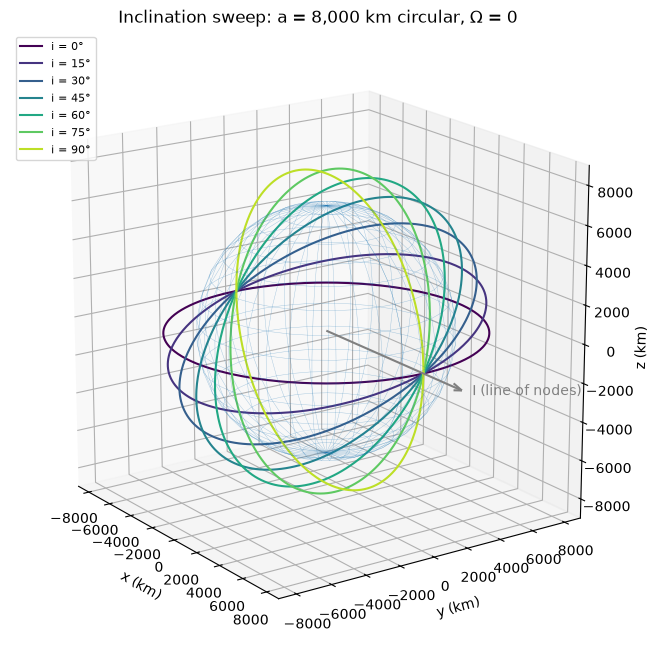

In [4]:
def orbit_track(a_km, e, i_deg, raan_deg, argp_deg, n_points=361):
    # Positions (n x 3, km) for one orbit, sweeping nu from 0 to 360 deg.
    nus = np.linspace(0.0, 360.0, n_points)
    return np.array([coe_to_rv(a_km, e, i_deg, raan_deg, argp_deg, nu)[0] for nu in nus])


def draw_earth(ax):
    u, w = np.meshgrid(np.linspace(0, 2 * np.pi, 36), np.linspace(0, np.pi, 18))
    ax.plot_wireframe(R_EARTH_KM * np.cos(u) * np.sin(w), R_EARTH_KM * np.sin(u) * np.sin(w),
                      R_EARTH_KM * np.cos(w), color="tab:blue", linewidth=0.3, alpha=0.4)


def set_equal(ax, limit):
    for setter in (ax.set_xlim, ax.set_ylim, ax.set_zlim):
        setter(-limit, limit)
    ax.set_box_aspect((1, 1, 1))
    ax.set_xlabel("x (km)"); ax.set_ylabel("y (km)"); ax.set_zlabel("z (km)")


inclinations = [0, 15, 30, 45, 60, 75, 90]
colours = plt.cm.viridis(np.linspace(0, 0.9, len(inclinations)))

fig = plt.figure(figsize=(8, 8))
ax = fig.add_subplot(projection="3d")
draw_earth(ax)
for i_deg, colour in zip(inclinations, colours):
    track = orbit_track(8000.0, 0.0, i_deg, 0.0, 0.0)
    ax.plot(*track.T, color=colour, linewidth=1.5, label=f"i = {i_deg}°")
ax.quiver(0, 0, 0, 11000, 0, 0, color="gray", arrow_length_ratio=0.06)
ax.text(11800, 0, 0, "I (line of nodes)", color="gray")
set_equal(ax, 9000)
ax.view_init(elev=18, azim=-35)
ax.set_title("Inclination sweep: a = 8,000 km circular, Ω = 0")
ax.legend(loc="upper left", fontsize=8)
fig.savefig(FIGURES_DIR / "ap2_inclination_sweep.png", dpi=150, bbox_inches="tight")
plt.show()

## D. Annotated orbit (figure 2)

a = 12,000 km, e = 0.3, i = 40°, Ω = 60°, ω = 45°, satellite at ν = 100°.

- **Ascending node:** where the satellite crosses the equator going north, at ν = −ω (u = 0).
- **Periapsis:** ν = 0, the closest point.
- **Velocity:** tangent to the orbit at the satellite.

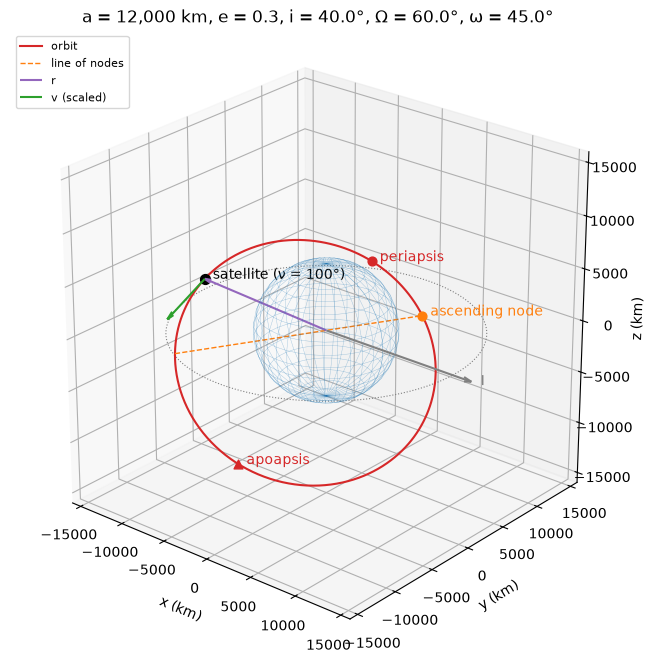

Check with rv_to_coe: {'a_km': 12000.0, 'e': 0.3, 'i_deg': 40.0, 'raan_deg': 60.0, 'argp_deg': 45.0, 'nu_deg': 100.0}


In [5]:
A, E_, I, RAAN, ARGP, NU = 12000.0, 0.3, 40.0, 60.0, 45.0, 100.0

track = orbit_track(A, E_, I, RAAN, ARGP)
r_sat, v_sat = coe_to_rv(A, E_, I, RAAN, ARGP, NU)
r_peri, _ = coe_to_rv(A, E_, I, RAAN, ARGP, 0.0)
r_apo, _ = coe_to_rv(A, E_, I, RAAN, ARGP, 180.0)
r_an, _ = coe_to_rv(A, E_, I, RAAN, ARGP, -ARGP)          # u = 0: ascending node
r_dn, _ = coe_to_rv(A, E_, I, RAAN, ARGP, 180.0 - ARGP)   # u = 180: descending node

fig = plt.figure(figsize=(8, 8))
ax = fig.add_subplot(projection="3d")
draw_earth(ax)
t = np.linspace(0, 2 * np.pi, 200)
ax.plot(14000 * np.cos(t), 14000 * np.sin(t), 0 * t, color="gray", linestyle=":", linewidth=0.8)
ax.plot(*track.T, color="tab:red", linewidth=1.5, label="orbit")
ax.plot(*np.array([r_dn, r_an]).T, color="tab:orange", linestyle="--", linewidth=1, label="line of nodes")

ax.scatter(*r_an, color="tab:orange", s=40)
ax.text(*r_an, "  ascending node", color="tab:orange")
ax.scatter(*r_peri, color="tab:red", s=40)
ax.text(*r_peri, "  periapsis", color="tab:red")
ax.scatter(*r_apo, color="tab:red", marker="^", s=40)
ax.text(*r_apo, "  apoapsis", color="tab:red")
ax.scatter(*r_sat, color="black", s=50)
ax.text(*r_sat, f"  satellite (ν = {NU:.0f}°)", color="black")

ax.quiver(0, 0, 0, *r_sat, color="tab:purple", arrow_length_ratio=0.05, label="r")
ax.quiver(*r_sat, *(v_sat * 900), color="tab:green", arrow_length_ratio=0.15, label="v (scaled)")
ax.quiver(0, 0, 0, 16000, 0, 0, color="gray", arrow_length_ratio=0.05)
ax.text(17000, 0, 0, "I", color="gray")

set_equal(ax, 16000)
ax.view_init(elev=25, azim=-50)
ax.set_title(f"a = {A:,.0f} km, e = {E_}, i = {I}°, Ω = {RAAN}°, ω = {ARGP}°")
ax.legend(loc="upper left", fontsize=8)
fig.savefig(FIGURES_DIR / "ap2_annotated_orbit.png", dpi=150, bbox_inches="tight")
plt.show()

print("Check with rv_to_coe:", {k: round(float(rv_to_coe(r_sat, v_sat)[k]), 3)
                               for k in ("a_km", "e", "i_deg", "raan_deg", "argp_deg", "nu_deg")})

## E. Time on the orbit (Kepler's equation)

Only ν changes in two-body motion. Mean anomaly M = n(t − t_p) advances steadily; Kepler's equation M = E − e sin E links it to the position.

Molniya period: 717.96 min
  reaches nu =  90 deg after   27.4 min
  reaches nu = 180 deg after  359.0 min
  reaches nu = 270 deg after  690.5 min
Fraction of the period between nu = 90 and 270 deg: 92.4%


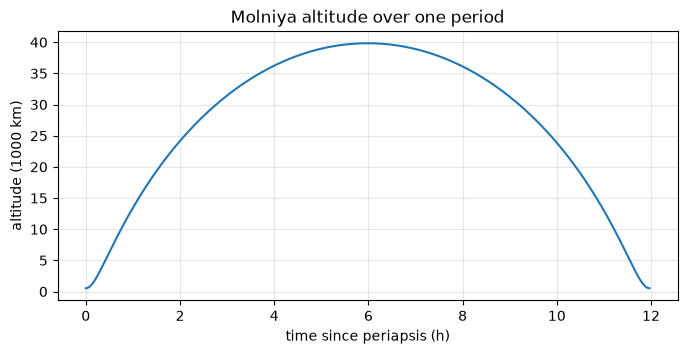

In [6]:
a, e = 26560.0, 0.74
print(f"Molniya period: {period_s(a) / 60:.2f} min")
for nu in (90, 180, 270):
    print(f"  reaches nu = {nu:3d} deg after {time_since_periapsis(a, e, nu) / 60:6.1f} min")

high = (time_since_periapsis(a, e, 270) - time_since_periapsis(a, e, 90)) / period_s(a)
print(f"Fraction of the period between nu = 90 and 270 deg: {high:.1%}")

times = np.linspace(0, period_s(a), 400)
altitudes = [np.linalg.norm(propagate(a, e, 63.4, 0.0, 270.0, 0.0, t)[0]) - R_EARTH_KM for t in times]

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(times / 3600, np.array(altitudes) / 1000)
ax.set_xlabel("time since periapsis (h)")
ax.set_ylabel("altitude (1000 km)")
ax.set_title("Molniya altitude over one period")
ax.grid(alpha=0.3)
plt.show()

## F. Which elements does a manoeuvre change cheaply?

**Shape and size: a, e.** A burn **along the velocity** (tangential) changes the orbit's energy, so a and e. It uses the full Δv to change speed, which is efficient.

**Orientation: i, Ω (and ω).** Changing i or Ω means **turning the velocity vector** to a new plane without changing its size. The cost is Δv = 2v sin(Δi/2), proportional to the orbital speed itself, which is large in LEO.

**Position: ν.** Changes by itself with time; moving along the orbit (phasing) is done by briefly changing a.

The comparison for the ISS-like orbit:

In [7]:
v_iss = np.linalg.norm(coe_to_rv(**REFERENCE)[1])
a_iss = REFERENCE["a_km"]

dv_raise_10km = (v_iss / 2) * (10.0 / a_iss)              # small change in a: dv ~ (v/2)(da/a)
dv_plane_1deg = 2 * v_iss * np.sin(np.radians(1.0) / 2)   # plane change of 1 deg

print(f"Orbital speed:              {v_iss:.3f} km/s")
print(f"Raise a by 10 km:           {dv_raise_10km * 1000:6.1f} m/s")
print(f"Change inclination by 1 deg:{dv_plane_1deg * 1000:7.1f} m/s")
print(f"Plane change costs {dv_plane_1deg / dv_raise_10km:.0f} x more")

Orbital speed:              7.672 km/s
Raise a by 10 km:              5.7 m/s
Change inclination by 1 deg:  133.9 m/s
Plane change costs 24 x more


**Result:** raising the ISS-like orbit by 10 km costs about 6 m/s; tilting it by just 1° costs about 134 m/s, over 20 times more. That is why launch vehicles aim for the right inclination directly, why plane changes are done where the orbital speed is lowest (at apoapsis, or combined with a large burn), and why constellations use Ω drift from J2 instead of thrust to spread their planes. Week 5 quantifies these manoeuvres properly.

## Stretch: live sliders

Requires `ipywidgets` (`%pip install ipywidgets`). Each slider redraws the orbit.

In [8]:
try:
    import ipywidgets as widgets
except ImportError:
    print("ipywidgets not installed: run  %pip install ipywidgets  then re-run this cell")
else:
    @widgets.interact(a_km=(6800, 42000, 200), e=(0.0, 0.8, 0.01), i_deg=(0, 180, 1),
                      raan_deg=(0, 359, 1), argp_deg=(0, 359, 1))
    def explore(a_km=12000, e=0.3, i_deg=40, raan_deg=60, argp_deg=45):
        track = orbit_track(a_km, e, i_deg, raan_deg, argp_deg)
        fig = plt.figure(figsize=(6, 6))
        ax = fig.add_subplot(projection="3d")
        draw_earth(ax)
        ax.plot(*track.T, color="tab:red")
        set_equal(ax, a_km * (1 + e))
        plt.show()

ipywidgets not installed: run  %pip install ipywidgets  then re-run this cell
